# TP: Machine Learning

## TP2: Classification (4h) 

In machine learning, classification is related to supervised learning approaches in which the algorithm fits from an annotated set of data. This learning phase is followed by a validation phase to evaluate the classification model through several metrics. Once the model is correctly validated, a generalization phase is used to classify new data.

The given dataset was produced by the World Health Organization. It pooled the evolution of 20 features for 15 years and among numerous countries. One of the goals of this TP2 is to visualize feature space and try to predict the development of countries.

**Objectives:**
- Visualize the feature space
- Discuss the feasibility of feature space separation
- Normalize the datasets
- Train a K-NN, a decision tree, a random forest and a SVM
- Visualize the decision boundary for each method
- Create a test dataset
- Compute AUC scores on a evaluation dataset
- Tune hyperparameters
- Visualize the modification of decision boundary for each tuning
- Discuss the limits of the four implementations

This TP has different **checkpoints**. Please call your teacher at the end of each checkpoint to validate your work. Any non validated work won't be taken into account in the notation


## STEP 1: Feature space visualization

You will work on the WHO dataset in the year 2000. This first step consists of choosing two features to perform a classification.

**TO DO 1.1**

If you are using jupyter-notebook, execute the following cell :

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors
import numpy as np

df = pd.read_csv("data/Life_Expectancy_Data.csv")
df = df.dropna()
df.info()

df1 = df[(df.Year == 2000)]
len(df1)

<class 'pandas.DataFrame'>
Index: 1649 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          1649 non-null   str    
 1   Year                             1649 non-null   int64  
 2   Status                           1649 non-null   str    
 3   Life_expectancy                  1649 non-null   float64
 4   Adult_mortality                  1649 non-null   float64
 5   Infant_deaths                    1649 non-null   int64  
 6   Alcohol                          1649 non-null   float64
 7   Percentage_expenditure           1649 non-null   float64
 8   Hepatitis_B                      1649 non-null   float64
 9   Measles                          1649 non-null   int64  
 10  BMI                              1649 non-null   float64
 11  Under-five_deaths                1649 non-null   int64  
 12  Polio                            164

61

61


<module 'matplotlib.pyplot' from 'c:\\Users\\moham\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\matplotlib\\pyplot.py'>

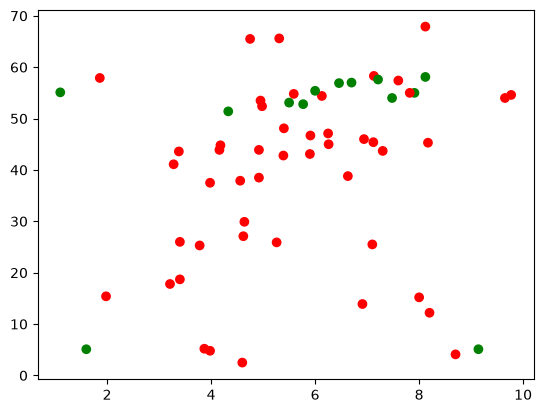

In [29]:
df_X = df1[['Total_expenditure', 'BMI']]
df_Status = df1[['Status']]

df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])
print (len(df_Y))
np1 = df_X.to_numpy()
plt.scatter(np1[:,0], np1[:,1], c=np.squeeze(df_Y.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))
plt

**QUESTION 1**

Why was the label status binarized?

Is this feature space easily separable? Justify your response

### -> Il est en binaire car il n'y a que deux options disponibles à la colonne "Status": ['Developing', 'Developed']. Cette caractéristique n'est pas parfaitement séparable car on peut observer qu'il y a des points en vert qui sont loins de la partie où la majorité se localise.

**TO CODE 1.2**

Plot Total expenditure against Schooling

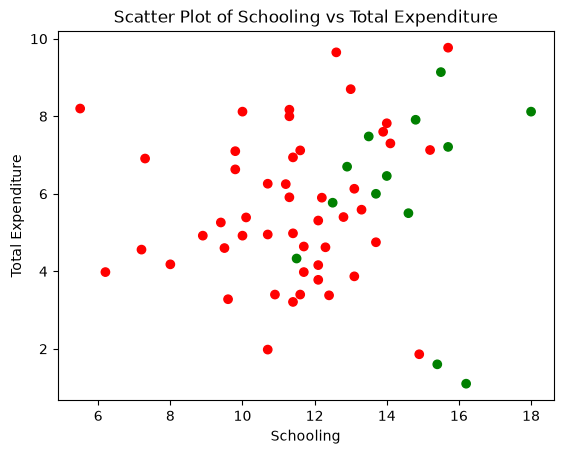

In [30]:
df_X = df1[['Schooling', 'Total_expenditure']]

df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])
plt.scatter(df_X['Schooling'], df_X['Total_expenditure'], c=np.squeeze(df_Y.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))
plt.xlabel("Schooling")
plt.ylabel("Total Expenditure")
plt.title("Scatter Plot of Schooling vs Total Expenditure")
plt.show()

**TO CODE 1.3**

Plot Life Expectancy against Schooling

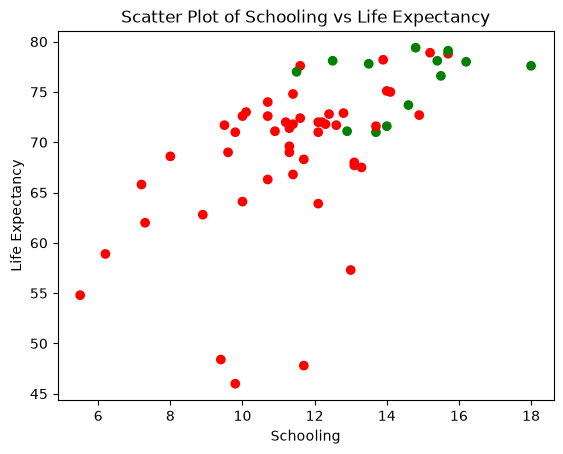

In [31]:
df_X = df1[['Life_expectancy', 'Schooling']]
df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])
plt.scatter(df_X['Schooling'], df_X['Life_expectancy'], c=np.squeeze(df_Y.to_numpy()), cmap=matplotlib.colors.ListedColormap(['red', 'green']))
plt.xlabel("Schooling")
plt.ylabel("Life Expectancy")
plt.title("Scatter Plot of Schooling vs Life Expectancy")
plt.show()

**QUESTION 2**

What would be the best features to use? Justify your response

Use those features as df_X.

### -> La meilleure caractéristique à utiliser est ['Life_expectancy', 'Schooling'] parce que la corrélation entre le niveau d'éducation et l'espérance de vie devient plus visible et on peut plus facilement séparer les pays developés de ceux en cours de developement.( Il y a des valeurs qui sont lointains de la majorité et puis on ne va pas les prendre en compte).

## Checkpoint : 1
Call your teacher to validate the first step of the TP

## STEP 2: Dataset normalization

To classify, the values in the learning dataset must be normalized (aka between 0 and 1). This normalization can be performed through various ways.

**TO CODE 2.1**

Normalize df_X. This normalization should perfectly frame the data (aka the minimum and the maximum values of each feature should be respectively 0 and 1).

In [32]:
max_life_expectancy = df_X['Life_expectancy'].max()
min_life_expectancy = df_X['Life_expectancy'].min()

max_schooling = df_X['Schooling'].max()
min_schooling = df_X['Schooling'].min()
print (min_life_expectancy, max_life_expectancy, min_schooling, max_schooling)
for i in range (len(df_X)):
    df_X.iloc[i, 0] = (df_X.iloc[i, 0] - min_life_expectancy) / (max_life_expectancy - min_life_expectancy)
    df_X.iloc[i, 1] = (df_X.iloc[i, 1] - min_schooling) / (max_schooling - min_schooling)
df_X


46.0 79.4 5.5 18.0


,Life_expectancy,Schooling
15,0.263473,0.000
31,0.796407,0.416
111,0.778443,0.456
143,0.961078,0.792
239,0.658683,0.608
...,...,...
2696,0.838323,0.416
2745,0.643713,0.624
2825,0.871257,0.680
2857,0.688623,0.328


**TO DO 2.2**

Each following cell performs a learning step and an AUC scores computation. For each classifier, several parameters have been chosen.

float64
float64
(61, 2)


c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neighbors\_classification.py:243: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


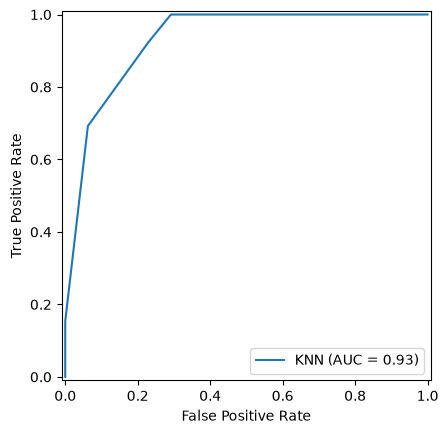

In [33]:
from sklearn import metrics
from sklearn.neighbors import KNeighborsClassifier

clf1 = KNeighborsClassifier(n_neighbors=5)

np_X_norm = df_X.to_numpy()
np_Y = df_Y.to_numpy().astype(np.float64)
print(np_X_norm.dtype)
print(np_Y.dtype)

clf1.fit(np_X_norm, np_Y)

np_Y_pred = clf1.predict_proba(np_X_norm)
print(np_Y_pred.shape)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='KNN')
display.plot()
plt.show()

c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


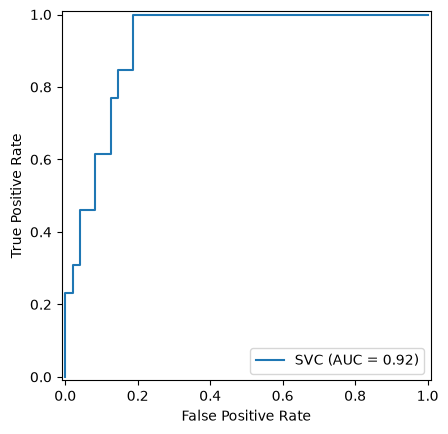

In [34]:
from sklearn.svm import SVC

clf2 = SVC(C=2.0, kernel='linear', probability=True)
clf2.fit(np_X_norm, np_Y)

np_Y_pred = clf2.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='SVC')
display.plot()
plt.show()

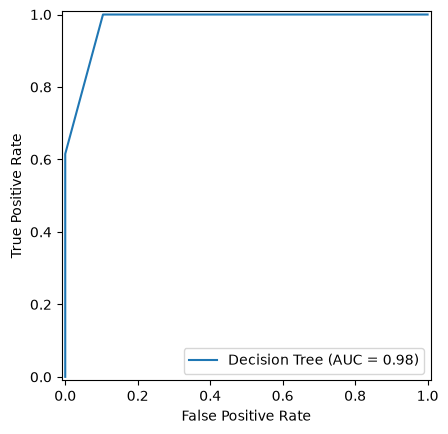

In [35]:
from sklearn.tree import DecisionTreeClassifier

clf3 = DecisionTreeClassifier(max_depth=3)
clf3.fit(np_X_norm, np_Y)

np_Y_pred = clf3.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='Decision Tree')
display.plot()
plt.show()

c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


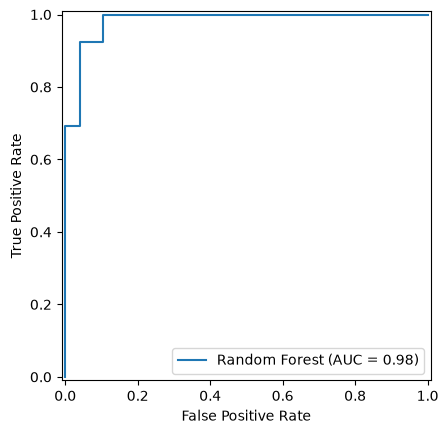

In [36]:
from sklearn.ensemble import RandomForestClassifier

clf4 = RandomForestClassifier(n_estimators=100, max_depth=3)
clf4.fit(np_X_norm, np_Y)

np_Y_pred = clf4.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='Random Forest')
display.plot()
plt.show()

**QUESTION 3**

Identify each used classifiers and specify the used parameters

Describe and explain the results obtained for each ROC curve. What is the relation between the AUC and the ROC curve ? According to the ROC curve, which model is the best if we want to maximize the sensitivity ? And if we want to maximize the specificity ? Compare those results with the AUC. 

### -> Les classifiers utilisés
* **KNN**: Le nombre de voisins(=5);
* **SVC** : La tolérance (=2), kernel/noyau( = "Lineaire");
* **DecisionTree** : profondeur de l'arbre ( =3);
* **RandomForest** : nombre d'estimateurs (= 100), profondeur de l'arbre(=3)


En se basant sur la courbe ROC et sur l'air AUC, on trouve que le meilleur classifieur est le **RandomForest** (AUC = 0.99), puis le **DecisionTree** (AUC = 0.98), ensuite le **KNN** (AUC= 0.93) et enfin le **SVC** (AUC= 0.92).
Pour maximiser la sensitivité (= TP), on doit choisir le **RandomForest** , et pour la sensitivité (1-FP), c'est aussi le **RandomForest**


For a two-classes problem, a decision boundary is a hypersurface which splits the feature space between two sets (for each class). Then this surface is composed of all the equiprobability points in the feature space.

**TO DO 2.3**

Plot the decision boundary with df_X for each classifiers

<module 'matplotlib.pyplot' from 'c:\\Users\\moham\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\matplotlib\\pyplot.py'>

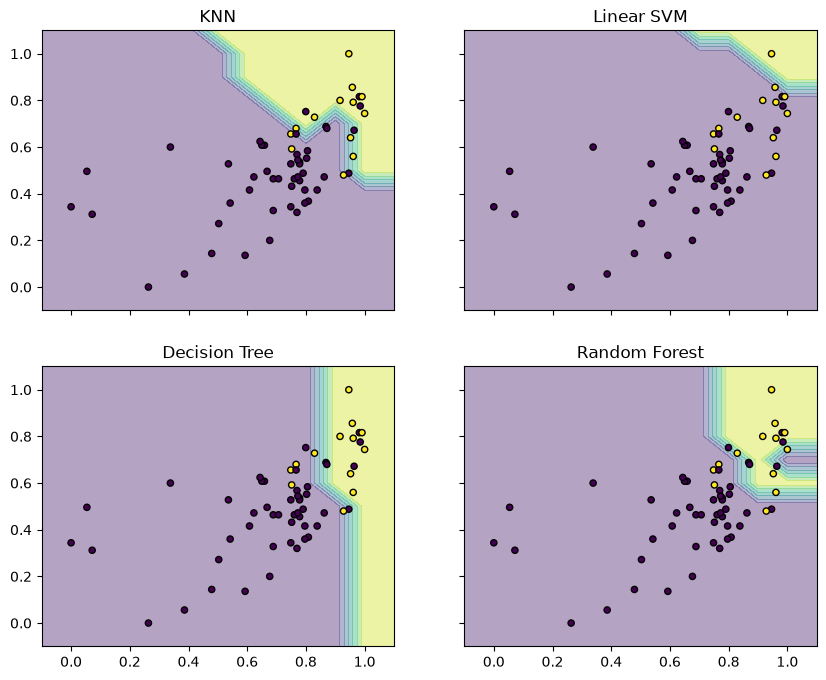

In [37]:
from itertools import product

x_min, x_max = np_X_norm[:, 0].min() - 0.1, np_X_norm[:, 0].max() + 0.1
y_min, y_max = np_X_norm[:, 1].min() - 0.1, np_X_norm[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

f, axarr = plt.subplots(2, 2, sharex='col', sharey='row', figsize=(10, 8))

for idx, clf, tt in zip(product([0, 1], [0, 1]),
                        [clf1, clf2, clf3, clf4],
                        ['KNN', 'Linear SVM', 'Decision Tree', 'Random Forest']):

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axarr[idx[0], idx[1]].contourf(xx, yy, Z, alpha=0.4)
    axarr[idx[0], idx[1]].scatter(np_X_norm[:, 0], np_X_norm[:, 1], c=np_Y,
                                  s=20, edgecolor='k')
    axarr[idx[0], idx[1]].set_title(tt)

plt

**QUESTION 4**

What is the main problem of the classification step with this dataset?

In your opinion, which classifier is better suited for this classification task? Justify your response

C'est le modèle KNN, puisqu'il prend le plus proche voisin pour classer les points pour dessiner les frontières, ce qui est plus efficace pour ce type de données.

## Checkpoint : 2
Call your teacher to validate the step 2

## STEP 3: Biases correction and model tuning

In this part, you will focus on improving the AUC scores of the four methods.

Firstable, you will weigh the classes to balance the classifier response. Then you will tune various hyperparameters.

**TO CODE 3.1**

Compute the percentage of "Developed" class in df_Y.

In [38]:
pr_developed = df_Y[df_Y == 1].sum() / len(df_Y)
pr_developed

Status    0.213115
dtype: object

SVM, Decision Tree and Random Forest algorithms have a parameter named:

```
class_weight
```
Here is a extract from sklearn documentation:

**class_weight** dict, list of dict or “balanced”, default=None

Weights associated with classes in the form {class_label: weight}. If None, all classes are supposed to have weight one. For multi-output problems, a list of dicts can be provided in the same order as the columns of y.

The “balanced” mode uses the values of y to automatically adjust weights inversely proportional to class frequencies in the input data.


**QUESTION 5**

What would be the weight values for each class?

Pour les pays developpés : w_1 = 1/0.213115
Pour les pays en developpement : w_1 = 1/(1-0.213115)

**TO CODE 3.2**

Balance SVM, Decision Tree and Random Forest classifiers and plot the decision boundaries

In [39]:
from sklearn.utils.class_weight import compute_sample_weight
compute_sample_weight(class_weight="balanced", y=df_Y.to_numpy().astype(np.float64))

array([0.63541667, 0.63541667, 0.63541667, 2.34615385, 0.63541667,
       2.34615385, 0.63541667, 0.63541667, 0.63541667, 0.63541667,
       2.34615385, 0.63541667, 0.63541667, 0.63541667, 2.34615385,
       0.63541667, 0.63541667, 0.63541667, 0.63541667, 0.63541667,
       0.63541667, 2.34615385, 0.63541667, 0.63541667, 0.63541667,
       0.63541667, 2.34615385, 0.63541667, 0.63541667, 0.63541667,
       2.34615385, 0.63541667, 2.34615385, 2.34615385, 0.63541667,
       0.63541667, 0.63541667, 0.63541667, 0.63541667, 0.63541667,
       0.63541667, 0.63541667, 0.63541667, 2.34615385, 2.34615385,
       2.34615385, 0.63541667, 0.63541667, 0.63541667, 0.63541667,
       2.34615385, 0.63541667, 0.63541667, 0.63541667, 0.63541667,
       0.63541667, 0.63541667, 0.63541667, 0.63541667, 0.63541667,
       0.63541667])

**TO CODE 3.3**

Compute the new AUC scores

c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


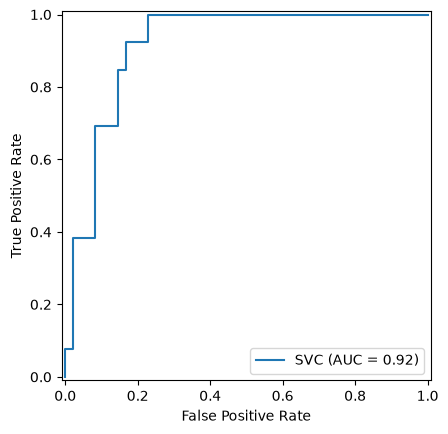

In [40]:


from sklearn.svm import SVC

clf2 = SVC(C=2.0, kernel='rbf', probability=True, class_weight="balanced")
clf2.fit(np_X_norm, np_Y)

np_Y_pred = clf2.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='SVC')
display.plot()
plt.show()



**QUESTION 6**

Why did the AUC scores increase? How do you interpret it?

In your opinion, has the classe balance improved the classification?


Let's focus on the SVM classifier.

Sklearn allows multiple kernels.

Here is an extract of the documentation:

**kernel** {‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’, ‘precomputed’}, default=’rbf’

Specifies the kernel type to be used in the algorithm. It must be one of ‘linear’, ‘poly’, ‘rbf’, ‘sigmoid’, ‘precomputed’ or a callable. If none is given, ‘rbf’ will be used. If a callable is given it is used to pre-compute the kernel matrix from data matrices; that matrix should be an array of shape (n_samples, n_samples).


**TO CODE 3.4**

Test the gaussian and the polynomial kernels with balanced classes and plot the decision boundaries

c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: Futu

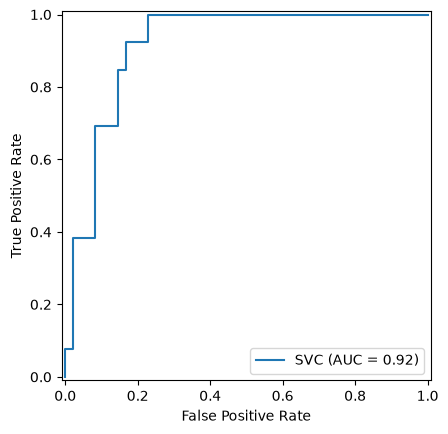

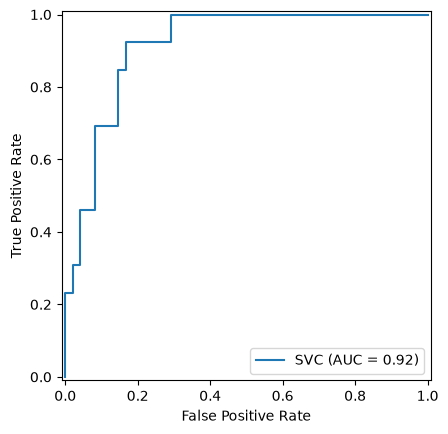

In [41]:
from sklearn.svm import SVC

clf2 = SVC(C=2.0, kernel='rbf', probability=True,class_weight="balanced")
clf2.fit(np_X_norm, np_Y)

np_Y_pred = clf2.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='SVC')
display.plot()
clf3 = SVC(C=2.0, kernel='poly', probability=True,class_weight="balanced")
clf3.fit(np_X_norm, np_Y)

np_Y_pred = clf3.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='SVC')
display.plot()
plt.show()

<module 'matplotlib.pyplot' from 'c:\\Users\\moham\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\matplotlib\\pyplot.py'>

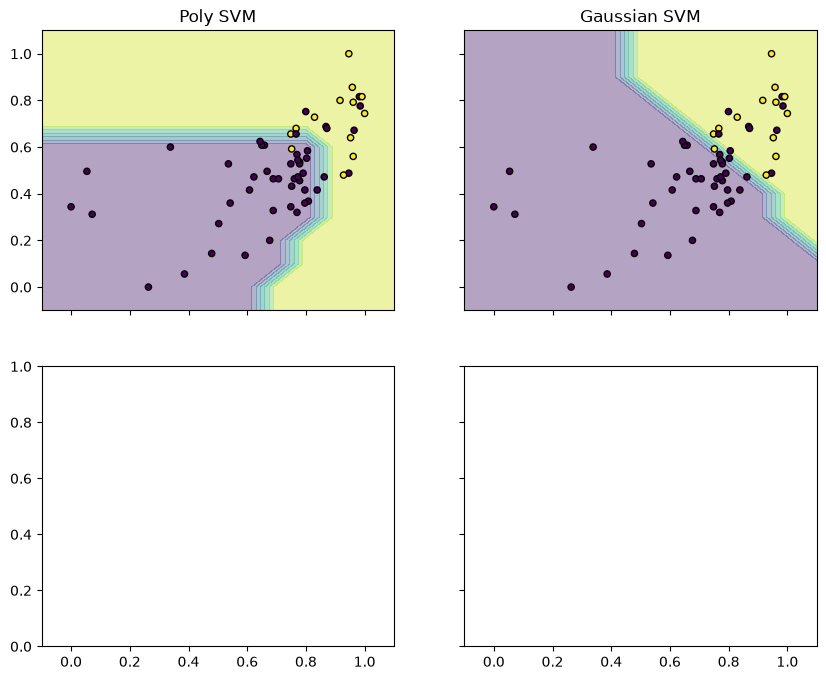

In [42]:
from itertools import product

x_min, x_max = np_X_norm[:, 0].min() - 0.1, np_X_norm[:, 0].max() + 0.1
y_min, y_max = np_X_norm[:, 1].min() - 0.1, np_X_norm[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

f, axarr = plt.subplots(2, 2, sharex='col', sharey='row', figsize=(10, 8))

for idx, clf, tt in zip(product([0, 1], [0, 1]),
                        [clf3, clf2],
                        ['Poly SVM', 'Gaussian SVM']):

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axarr[idx[0], idx[1]].contourf(xx, yy, Z, alpha=0.4)
    axarr[idx[0], idx[1]].scatter(np_X_norm[:, 0], np_X_norm[:, 1], c=np_Y,
                                  s=20, edgecolor='k')
    axarr[idx[0], idx[1]].set_title(tt)

plt

**QUESTION 7**

In your opinion, which is the best kernel for this dataset? Justify your response

Le noyau Gaussien est le meilleur pour cette dataset. La barriere est plus linéaire et n'a pas de variations brutes.

**BONUS**

Tune the parameters for Decision Tree and Random Forest algorithms and plot the decision boundaries

c:\Users\moham\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


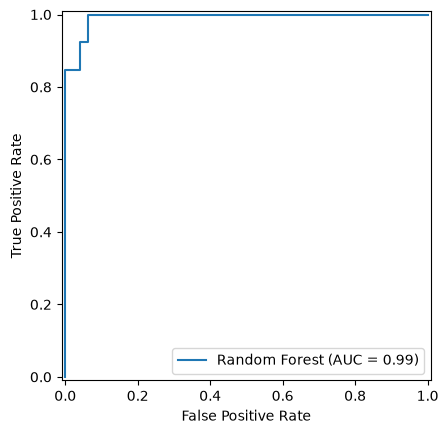

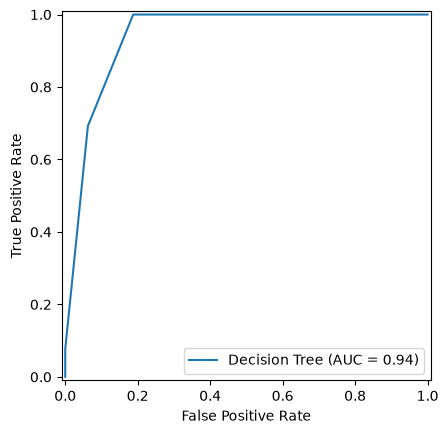

<module 'matplotlib.pyplot' from 'c:\\Users\\moham\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\matplotlib\\pyplot.py'>

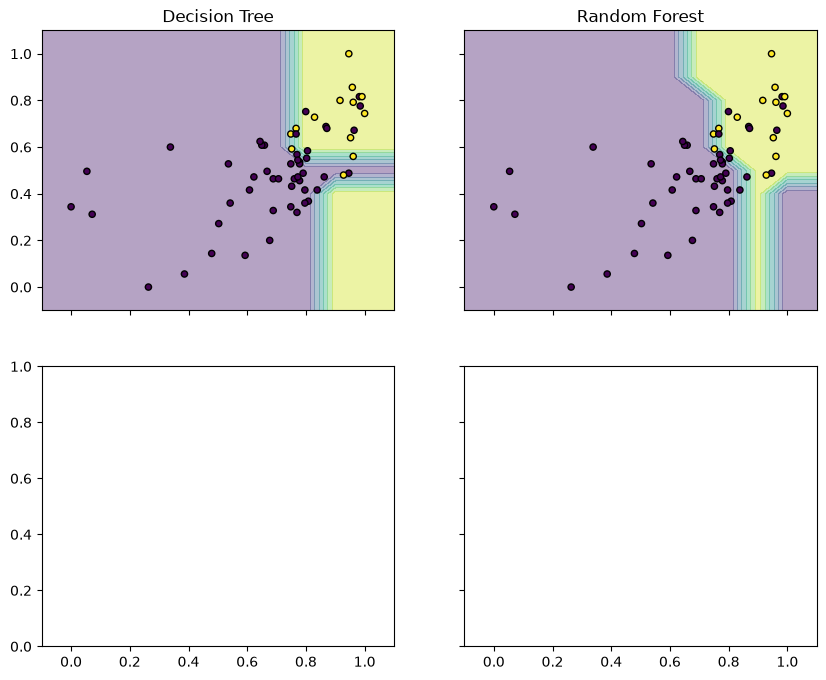

In [43]:
from sklearn.ensemble import RandomForestClassifier

clf4 = RandomForestClassifier(n_estimators=100, max_depth=3,class_weight="balanced")
clf4.fit(np_X_norm, np_Y)

np_Y_pred = clf4.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='Random Forest')
display.plot()
plt.show()

from sklearn.tree import DecisionTreeClassifier

clf5 = DecisionTreeClassifier(max_depth=3, class_weight="balanced")
clf5.fit(np_X_norm, np_Y)

np_Y_pred = clf5.predict_proba(np_X_norm)

fpr, tpr, thresholds = metrics.roc_curve(np_Y, np_Y_pred[:,1])
roc_auc = metrics.auc(fpr, tpr)
display = metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   name='Decision Tree')
display.plot()
plt.show()

from itertools import product

x_min, x_max = np_X_norm[:, 0].min() - 0.1, np_X_norm[:, 0].max() + 0.1
y_min, y_max = np_X_norm[:, 1].min() - 0.1, np_X_norm[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

f, axarr = plt.subplots(2, 2, sharex='col', sharey='row', figsize=(10, 8))

for idx, clf, tt in zip(product([0, 1], [0, 1]),
                        [clf5, clf4],
                        ['Decision Tree', 'Random Forest']):

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axarr[idx[0], idx[1]].contourf(xx, yy, Z, alpha=0.4)
    axarr[idx[0], idx[1]].scatter(np_X_norm[:, 0], np_X_norm[:, 1], c=np_Y,
                                  s=20, edgecolor='k')
    axarr[idx[0], idx[1]].set_title(tt)

plt

## Checkpoint : 3
Call your teacher to validate step 3

## STEP 4: An evaluation dataset

This part is to test the generalization of your models.

You trained several classifiers on two features extracted from the year 2000.

**TO CODE 4.1**

Apply your models on the year 2012

<module 'matplotlib.pyplot' from 'c:\\Users\\moham\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\matplotlib\\pyplot.py'>

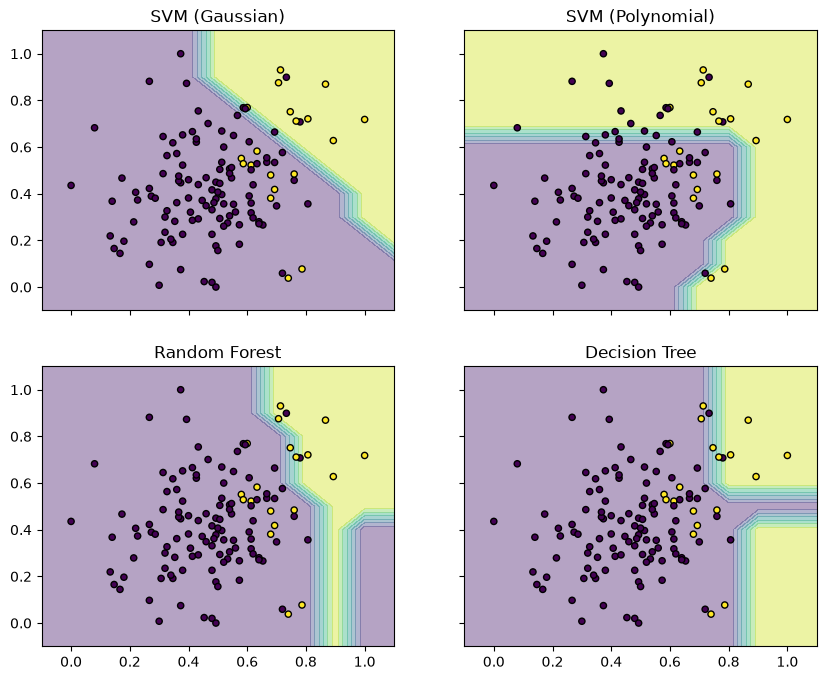

In [45]:
df2 = df[(df.Year == 2012)]
df_X = df2[[ 'Schooling', 'Total_expenditure']]
max_total_expenditure = df_X['Total_expenditure'].max()
min_total_expenditure = df_X['Total_expenditure'].min()
df_X['Total_expenditure'] = (df_X['Total_expenditure'] - min_total_expenditure) / (max_total_expenditure - min_total_expenditure)
max_schooling = df_X['Schooling'].max()
min_schooling = df_X['Schooling'].min()
df_X['Schooling'] = (df_X['Schooling'] - min_schooling) / (max_schooling - min_schooling)
df_Status = df2[['Status']]
df_Y = df_Status.replace(['Developing', 'Developed'], [0, 1])
np_X_norm = df_X.to_numpy()
np_Y = df_Y.to_numpy().astype(np.float64)

from itertools import product

x_min, x_max = np_X_norm[:, 0].min() - 0.1, np_X_norm[:, 0].max() + 0.1
y_min, y_max = np_X_norm[:, 1].min() - 0.1, np_X_norm[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

f, axarr = plt.subplots(2, 2, sharex='col', sharey='row', figsize=(10, 8))

for idx, clf, tt in zip(product([0, 1], [0, 1]),
                        [clf2, clf3, clf4, clf5],
                        ['SVM (Gaussian)', 'SVM (Polynomial)', 'Random Forest', 'Decision Tree']):

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axarr[idx[0], idx[1]].contourf(xx, yy, Z, alpha=0.4)
    axarr[idx[0], idx[1]].scatter(np_X_norm[:, 0], np_X_norm[:, 1], c=np_Y,
                                  s=20, edgecolor='k')
    axarr[idx[0], idx[1]].set_title(tt)

plt

**QUESTION 8**

Are your models still relevant in the year 2012?

Les modèles ne sont pas très pertinents avec le jeu de données de 2012. Il apparait que les pays développés ont une scolarisation et une espérance de vie élevées, pourtant plusieurs pays développés tombent dans la zone des pays en développement.Le SVM polynomial semble qu'il identifie le plus les pays developpés, mais il a inclut aussi des pays en developpement comme des pays developpés.

## Checkpoint : 4
Call your teacher to validate step 4. Congrats, you finished the second TP !